In [1]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if 'Mosaic_ADL_2x2' in dirs:
        print(os.path.join(root, 'Mosaic_ADL_2x2'))
        break

/kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2


[INFO] Using DATA_ROOT: /kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living
[INFO] Using DATA_ROOT: /kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living
[INFO] 19 classes, fixed order: ['D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19']
[INFO] Total images indexed: 16437
class_name
Walking_Slow           1476
Walking_Fast           1508
Jogging_Slow           1509
Jogging_Fast           1433
Stairs_Slow            1685
Stairs_Fast            1041
Sit_HalfHeight_Slow     570
Sit_HalfHeight_Fast     570
Sit_LowHeight_Slow      555
Sit_LowHeight_Fast      555
Collapse_Into_Chair     569
Lying_Slow_SitAgain     570
Lying_Fast_SitAgain     360
Back_Lateral_Change     570
Standing_KneeBend       570
Standing_NoKneeBend     569
Car_InOut              1607
St

100%|██████████| 82.7M/82.7M [00:00<00:00, 152MB/s]



STAGE 7a: Training classifier head only (backbone frozen)
[Head] Epoch 1/8 (global 1) | train_loss=1.8579 train_acc=0.5002 | val_loss=1.3406 val_acc=0.6356
    -> New best model saved (val_acc=0.6356)
[Head] Epoch 2/8 (global 2) | train_loss=1.3522 train_acc=0.6135 | val_loss=1.1100 val_acc=0.6852
    -> New best model saved (val_acc=0.6852)
[Head] Epoch 3/8 (global 3) | train_loss=1.1880 train_acc=0.6493 | val_loss=1.0140 val_acc=0.7096
    -> New best model saved (val_acc=0.7096)
[Head] Epoch 4/8 (global 4) | train_loss=1.1095 train_acc=0.6682 | val_loss=0.9649 val_acc=0.7129
    -> New best model saved (val_acc=0.7129)
[Head] Epoch 5/8 (global 5) | train_loss=1.0609 train_acc=0.6759 | val_loss=0.9168 val_acc=0.7300
    -> New best model saved (val_acc=0.7300)
[Head] Epoch 6/8 (global 6) | train_loss=1.0240 train_acc=0.6933 | val_loss=0.9128 val_acc=0.7300
[Head] Epoch 7/8 (global 7) | train_loss=0.9895 train_acc=0.6943 | val_loss=0.8876 val_acc=0.7349
    -> New best model saved (v

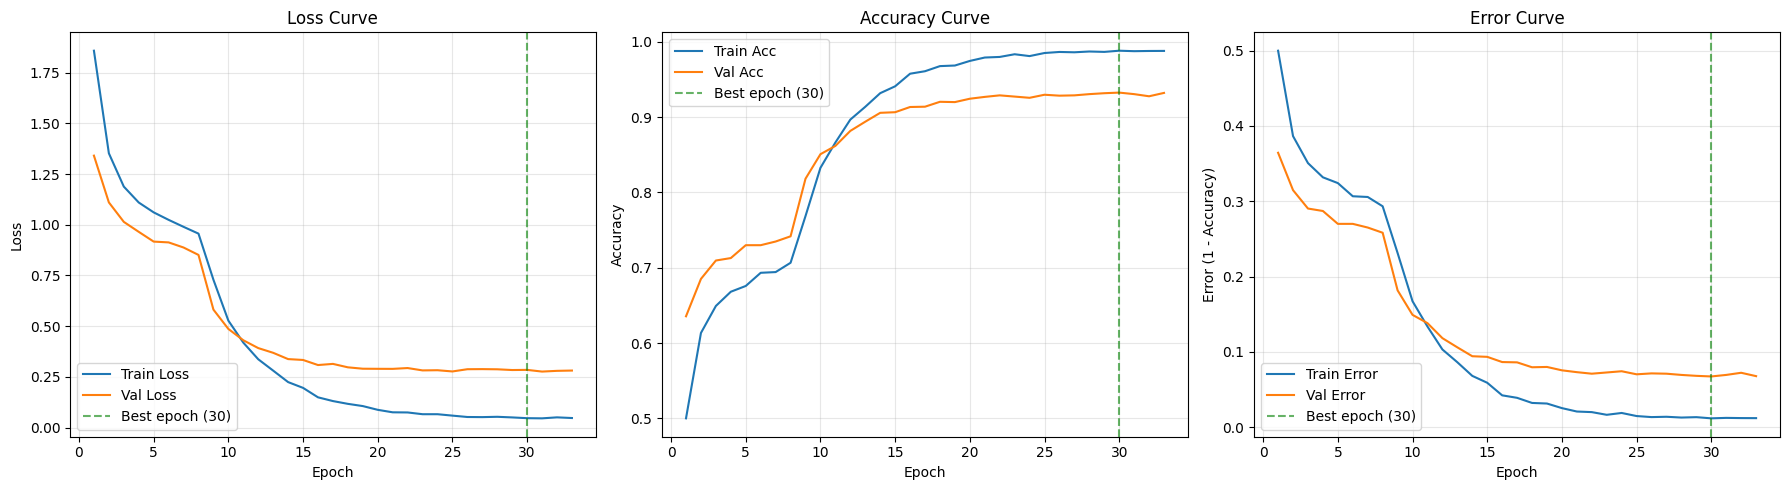

[INFO] Curves saved to /kaggle/working/training_curves.png

TEST SET CLASSIFICATION REPORT
                     precision    recall  f1-score   support

       Walking_Slow     0.9910    0.9910    0.9910       222
       Walking_Fast     0.9956    0.9956    0.9956       227
       Jogging_Slow     0.9782    0.9868    0.9825       227
       Jogging_Fast     0.9953    0.9722    0.9836       216
        Stairs_Slow     0.9766    0.9843    0.9804       254
        Stairs_Fast     0.9682    0.9682    0.9682       157
Sit_HalfHeight_Slow     0.6822    0.8488    0.7565        86
Sit_HalfHeight_Fast     0.8876    0.9186    0.9029        86
 Sit_LowHeight_Slow     0.8387    0.6190    0.7123        84
 Sit_LowHeight_Fast     0.8831    0.8095    0.8447        84
Collapse_Into_Chair     0.9518    0.9186    0.9349        86
Lying_Slow_SitAgain     0.8966    0.9070    0.9017        86
Lying_Fast_SitAgain     0.8571    0.8727    0.8649        55
Back_Lateral_Change     0.9318    0.9535    0.9425    

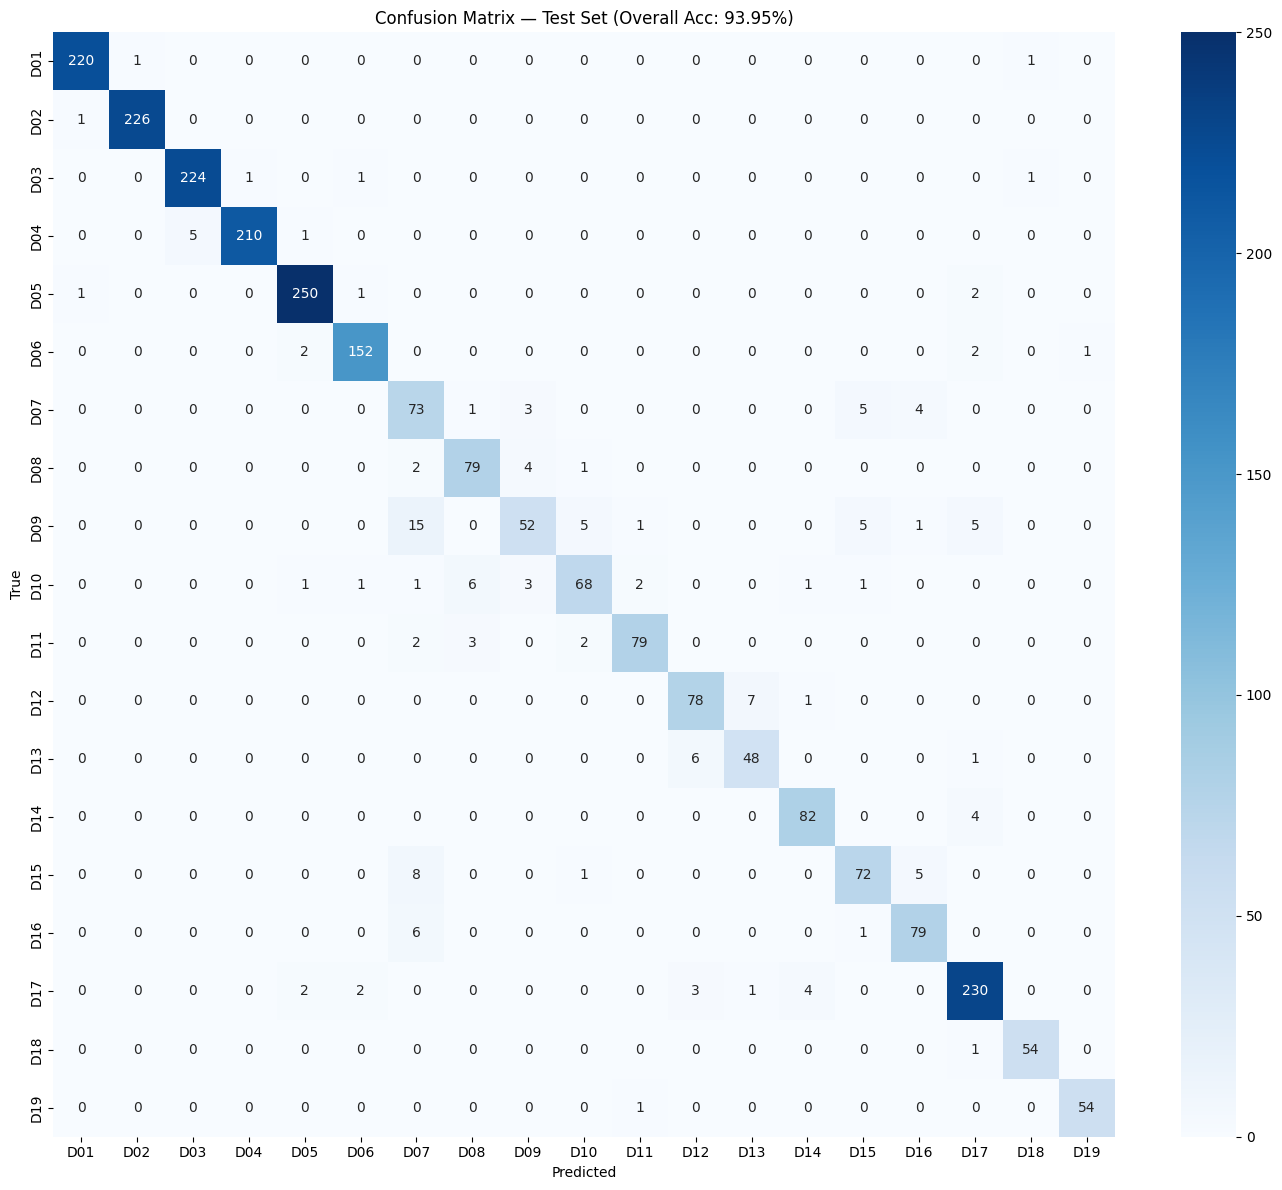


[DONE] All artifacts saved under /kaggle/working:
  - best_efficientnetv2s_adl.pt   (best checkpoint by val accuracy)
  - training_curves.png           (loss / accuracy / error curves)
  - confusion_matrix.png
  - classification_report.txt
  - per_class_metrics.csv         (TP/TN/FP/FN/Precision/Recall/Specificity/F1)
  - split_train.csv / split_val.csv / split_test.csv  (exact split used, auditable)


In [2]:
"""
=======================================================================================
ADL Activity Classification — EfficientNetV2-S — SisFall Mosaic_ADL_2x2 (Daily Living)
=======================================================================================
Run this on Kaggle (GPU T4 x2 or P100 enabled, Internet = On).

Dataset expected at (auto-detected below, but verify path once with the print at top):
  /kaggle/input/<your-dataset-slug>/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living/
        {ActivityLabel}/{subject}/{stem}.png

Mosaic layout being trained on (this matters for interpreting results, not for code):
    Column 0 = Scalogram        Column 1 = Spectrogram
Row0 (Acc1)  [ Acc1_scalogram ]  [ Acc1_spectrogram ]
Row1 (Gyro)  [ Gyro_scalogram ]  [ Gyro_spectrogram ]
Canvas = 2*188 + 1*8(gutter) = 384 x 384  -> exact native EfficientNetV2-S input.
Because every single image in the dataset shares this identical fixed layout, the
network only ever needs to learn "top row = Acc1, bottom row = Gyro; left col =
scalogram, right col = spectrogram" once — the 8px black gutter acts as a hard
spatial boundary so early conv filters don't blend content across sensor/representation
quadrants. No special multi-branch architecture is needed for this reason alone.
=======================================================================================
"""

import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import confusion_matrix, classification_report

# ---------------------------------------------------------------------------------------
# 0. REPRODUCIBILITY
# ---------------------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------------------------------------------------------------------------------------
# 1. PATHS  (edit DATASET_SLUG to match your actual Kaggle input folder name)
# ---------------------------------------------------------------------------------------
DATASET_SLUG = "dataset-for-fall-and-activity-detection"   # from your dataset title, auto-slugified
DATA_ROOT = "/kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living"

if not os.path.isdir(DATA_ROOT):
    raise FileNotFoundError(
        f"DATA_ROOT not found: {DATA_ROOT}\n"
        f"Run: os.listdir('.../Mosaic_ADL_2x2') to confirm the exact subfolder name/spelling."
    )
print(f"[INFO] Using DATA_ROOT: {DATA_ROOT}")

if not os.path.isdir(DATA_ROOT):
    # fallback: search for it under /kaggle/input in case the slug differs
    candidates = glob.glob("/kaggle/input/*/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living")
    if candidates:
        DATA_ROOT = candidates[0]
        print(f"[INFO] DATASET_SLUG guess was wrong — auto-found dataset at:\n  {DATA_ROOT}")
    else:
        raise FileNotFoundError(
            "Could not find 'Mosaic_ADL_2x2/Daily Living' under /kaggle/input. "
            "Check Add Input -> your dataset is attached, and verify the folder name."
        )

print(f"[INFO] Using DATA_ROOT: {DATA_ROOT}")

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------------------------------------
# 2. ACTIVITY LABEL <-> CLASS INDEX MAPPING (fixed order D01..D19, not alphabetical)
#    This matters: ImageFolder-style alphabetical sorting would scramble D-code order,
#    which makes later confusion-matrix reading/reporting harder to map back to D-codes.
# ---------------------------------------------------------------------------------------
ACTIVITY_LABELS = {
    'D01': 'Walking_Slow', 'D02': 'Walking_Fast', 'D03': 'Jogging_Slow', 'D04': 'Jogging_Fast',
    'D05': 'Stairs_Slow', 'D06': 'Stairs_Fast',
    'D07': 'Sit_HalfHeight_Slow', 'D08': 'Sit_HalfHeight_Fast',
    'D09': 'Sit_LowHeight_Slow', 'D10': 'Sit_LowHeight_Fast',
    'D11': 'Collapse_Into_Chair', 'D12': 'Lying_Slow_SitAgain', 'D13': 'Lying_Fast_SitAgain',
    'D14': 'Back_Lateral_Change', 'D15': 'Standing_KneeBend', 'D16': 'Standing_NoKneeBend',
    'D17': 'Car_InOut', 'D18': 'Stumble_Walking', 'D19': 'Gentle_Jump',
}
CODE_ORDER = list(ACTIVITY_LABELS.keys())                       # ['D01', ..., 'D19']
LABEL_TO_CODE = {v: k for k, v in ACTIVITY_LABELS.items()}
CLASS_NAMES = [ACTIVITY_LABELS[c] for c in CODE_ORDER]           # index 0..18, fixed order
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
print(f"[INFO] {NUM_CLASSES} classes, fixed order: {CODE_ORDER}")

# ---------------------------------------------------------------------------------------
# 3. BUILD FILE INDEX  (one row per image: filepath, class_name, class_idx, subject)
# ---------------------------------------------------------------------------------------
records = []
for class_name in CLASS_NAMES:
    class_dir = os.path.join(DATA_ROOT, class_name)
    if not os.path.isdir(class_dir):
        print(f"[WARN] Missing folder for class '{class_name}' at {class_dir} — skipping.")
        continue
    subject_dirs = sorted(os.listdir(class_dir))
    for subject in subject_dirs:
        subject_path = os.path.join(class_dir, subject)
        if not os.path.isdir(subject_path):
            continue
        for fpath in glob.glob(os.path.join(subject_path, "*.png")):
            records.append({
                "filepath": fpath,
                "class_name": class_name,
                "class_idx": CLASS_TO_IDX[class_name],
                "subject": subject,
            })

df = pd.DataFrame(records)
assert len(df) > 0, "No images found — check DATA_ROOT and folder structure."
print(f"[INFO] Total images indexed: {len(df)}")
print(df.groupby("class_name").size().reindex(CLASS_NAMES))   # per-class image counts, sanity check

# ---------------------------------------------------------------------------------------
# 4. CLASS-WISE (STRATIFIED) 70/15/15 SPLIT — as required: split WITHIN each activity
#    so every class is independently divided 70/15/15, not split globally.
#    Uses numpy shuffling with a fixed seed for reproducibility.
# ---------------------------------------------------------------------------------------
def stratified_split(df, train_frac=0.70, val_frac=0.15, seed=SEED):
    train_parts, val_parts, test_parts = [], [], []
    rng = np.random.default_rng(seed)
    for class_name, group in df.groupby("class_name"):
        idx = group.index.to_numpy()
        rng.shuffle(idx)                       # numpy-based shuffle, per class
        n = len(idx)
        n_train = int(np.floor(n * train_frac))
        n_val = int(np.floor(n * val_frac))
        train_idx = idx[:n_train]
        val_idx = idx[n_train:n_train + n_val]
        test_idx = idx[n_train + n_val:]       # remainder -> test (handles rounding)
        train_parts.append(df.loc[train_idx])
        val_parts.append(df.loc[val_idx])
        test_parts.append(df.loc[test_idx])
    train_df = pd.concat(train_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = pd.concat(val_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    test_df = pd.concat(test_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df, test_df

train_df, val_df, test_df = stratified_split(df)
print(f"[INFO] Split sizes -> train: {len(train_df)}  val: {len(val_df)}  test: {len(test_df)}")

# Sanity check: confirm every class is present with roughly the right ratio in every split
print("\n[INFO] Per-class split verification (should be ~70/15/15 for every class):")
check = pd.DataFrame({
    "train": train_df.groupby("class_name").size(),
    "val": val_df.groupby("class_name").size(),
    "test": test_df.groupby("class_name").size(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
print(check)

# Save split manifests so the exact split is reproducible/auditable later
train_df.to_csv(os.path.join(OUTPUT_DIR, "split_train.csv"), index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR, "split_val.csv"), index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR, "split_test.csv"), index=False)

# ---------------------------------------------------------------------------------------
# 5. DATASET / DATALOADER
# ---------------------------------------------------------------------------------------
IMG_SIZE = 384
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),   # safety no-op if already 384x384
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
# NOTE: no horizontal flip / color jitter here on purpose (see pipeline plan notes) —
# flipping reverses the time axis (destroys before/after causal structure), and
# color/hue jitter would distort the colormap-encoded signal magnitude.

class MosaicDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["filepath"]).convert("RGB")
        img = self.transform(img)
        label = int(row["class_idx"])
        return img, label

BATCH_SIZE = 32
NUM_WORKERS = 2  # Kaggle notebooks: keep modest, raise if you have headroom

train_ds = MosaicDataset(train_df, train_transform)
val_ds = MosaicDataset(val_df, eval_transform)
test_ds = MosaicDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

# ---------------------------------------------------------------------------------------
# 6. CLASS-WEIGHTED LOSS  (your class counts differ ~3x between D01-D04/D05,06,17 groups
#    and D07-D16/D18/D19 groups — weighting prevents the model from just learning to favor
#    the bigger classes)
# ---------------------------------------------------------------------------------------
class_counts = train_df.groupby("class_idx").size().reindex(range(NUM_CLASSES)).fillna(1).to_numpy()
class_weights = (1.0 / class_counts)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)
print(f"\n[INFO] Class weights (train-set based): {np.round(class_weights, 3)}")

# ---------------------------------------------------------------------------------------
# 7. MODEL — EfficientNetV2-S, ImageNet-pretrained, native 384x384 input
# ---------------------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] Device: {device}")

model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
in_feats = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_feats, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor.to(device))

# ---------------------------------------------------------------------------------------
# 8. TWO-STAGE FINE-TUNING SETUP
# ---------------------------------------------------------------------------------------
HEAD_EPOCHS = 8          # Stage 7a: classifier head only
FINE_TUNE_EPOCHS = 25    # Stage 7b: unfreeze last blocks
EARLY_STOP_PATIENCE = 7

def set_backbone_trainable(model, trainable_last_n_blocks=0):
    """Freeze everything; optionally unfreeze the last N feature blocks + classifier."""
    for p in model.features.parameters():
        p.requires_grad = False
    for p in model.classifier.parameters():
        p.requires_grad = True
    if trainable_last_n_blocks > 0:
        for block in list(model.features.children())[-trainable_last_n_blocks:]:
            for p in block.parameters():
                p.requires_grad = True

# ---------------------------------------------------------------------------------------
# 9. TRAIN / VALIDATE LOOP  (shared by both stages; tracks loss + accuracy per epoch)
# ---------------------------------------------------------------------------------------
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_epoch = -1
epochs_no_improve = 0
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "best_efficientnetv2s_adl.pt")

def run_epoch(loader, model, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    running_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(is_train)
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        if is_train:
            optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        if is_train:
            loss.backward()
            optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def train_stage(model, optimizer, n_epochs, stage_name):
    global best_val_acc, best_epoch, epochs_no_improve
    for epoch in range(n_epochs):
        train_loss, train_acc = run_epoch(train_loader, model, criterion, optimizer)
        val_loss, val_acc = run_epoch(val_loader, model, criterion, optimizer=None)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        global_epoch = len(history["train_loss"])
        print(f"[{stage_name}] Epoch {epoch+1}/{n_epochs} (global {global_epoch}) | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = global_epoch
            epochs_no_improve = 0
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            print(f"    -> New best model saved (val_acc={val_acc:.4f})")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= EARLY_STOP_PATIENCE:
                print(f"    -> Early stopping ({stage_name}): no val improvement in "
                      f"{EARLY_STOP_PATIENCE} epochs.")
                return True   # signal: stop
    return False

# --- Stage 7a: head-only ---
print("\n" + "=" * 60)
print("STAGE 7a: Training classifier head only (backbone frozen)")
print("=" * 60)
set_backbone_trainable(model, trainable_last_n_blocks=0)
optimizer_head = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-4
)
train_stage(model, optimizer_head, HEAD_EPOCHS, "Head")

# --- Stage 7b: fine-tune last blocks + head ---
print("\n" + "=" * 60)
print("STAGE 7b: Fine-tuning last 3 backbone blocks + head")
print("=" * 60)
set_backbone_trainable(model, trainable_last_n_blocks=3)
optimizer_ft = optim.Adam([
    {"params": [p for n, p in model.features.named_parameters() if p.requires_grad], "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4},
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=FINE_TUNE_EPOCHS)

epochs_no_improve = 0  # reset patience counter for the new stage
for epoch in range(FINE_TUNE_EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, model, criterion, optimizer_ft)
    val_loss, val_acc = run_epoch(val_loader, model, criterion, optimizer=None)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    global_epoch = len(history["train_loss"])
    print(f"[FineTune] Epoch {epoch+1}/{FINE_TUNE_EPOCHS} (global {global_epoch}) | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | lr={scheduler.get_last_lr()}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = global_epoch
        epochs_no_improve = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"    -> New best model saved (val_acc={val_acc:.4f})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"    -> Early stopping (FineTune): no val improvement in "
                  f"{EARLY_STOP_PATIENCE} epochs.")
            break

print(f"\n[INFO] Best model: global epoch {best_epoch}, val_acc={best_val_acc:.4f}")
print(f"[INFO] Best checkpoint saved at: {BEST_MODEL_PATH}")

# ---------------------------------------------------------------------------------------
# 10. LOSS / ACCURACY / ERROR CURVES
# ---------------------------------------------------------------------------------------
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss")
axes[0].axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], label="Train Acc")
axes[1].plot(epochs_range, history["val_acc"], label="Val Acc")
axes[1].axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[1].set_title("Accuracy Curve")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)

train_err = [1 - a for a in history["train_acc"]]
val_err = [1 - a for a in history["val_acc"]]
axes[2].plot(epochs_range, train_err, label="Train Error")
axes[2].plot(epochs_range, val_err, label="Val Error")
axes[2].axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
axes[2].set_title("Error Curve")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Error (1 - Accuracy)"); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=150)
plt.show()
print(f"[INFO] Curves saved to {OUTPUT_DIR}/training_curves.png")

# ---------------------------------------------------------------------------------------
# 11. FINAL TEST-SET EVALUATION USING THE BEST CHECKPOINT
# ---------------------------------------------------------------------------------------
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(preds.tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\n" + "=" * 60)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 60)
report_str = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report_str)
with open(os.path.join(OUTPUT_DIR, "classification_report.txt"), "w") as f:
    f.write(report_str)

overall_acc = (y_true == y_pred).mean()
print(f"\n[RESULT] Overall test accuracy: {overall_acc*100:.2f}%")

# ---------------------------------------------------------------------------------------
# 12. PER-CLASS TP / TN / FP / FN + PRECISION / RECALL(SENSITIVITY) / SPECIFICITY / F1
#     (one-vs-rest, computed manually from the multiclass confusion matrix)
# ---------------------------------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

rows = []
for i, class_name in enumerate(CLASS_NAMES):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall_sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0.0     # = Sensitivity
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
    f1 = (2 * precision * recall_sensitivity / (precision + recall_sensitivity)
          if (precision + recall_sensitivity) > 0 else 0.0)

    rows.append({
        "D_code": CODE_ORDER[i],
        "Activity": class_name,
        "TP": TP, "TN": TN, "FP": FP, "FN": FN,
        "Precision": round(precision, 4),
        "Recall_Sensitivity": round(recall_sensitivity, 4),
        "Specificity": round(specificity, 4),
        "F1_Score": round(f1, 4),
    })

metrics_df = pd.DataFrame(rows)
print("\n" + "=" * 60)
print("PER-CLASS TP/TN/FP/FN + PRECISION/RECALL/SPECIFICITY/F1")
print("=" * 60)
print(metrics_df.to_string(index=False))
metrics_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)

# Priority-flag D18 (stumble) and near-fall-neighbor classes explicitly, since these
# matter most for the downstream PatchCore-routing stage of the overall pipeline.
priority_codes = ["D18", "D01", "D02", "D07", "D08", "D09", "D10", "D11", "D12", "D13"]
print("\n[PRIORITY CHECK] Highest-risk classes for downstream PatchCore routing:")
print(metrics_df[metrics_df["D_code"].isin(priority_codes)].to_string(index=False))

# ---------------------------------------------------------------------------------------
# 13. CONFUSION MATRIX HEATMAP
# ---------------------------------------------------------------------------------------
import seaborn as sns

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CODE_ORDER, yticklabels=CODE_ORDER, cbar=True)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix — Test Set (Overall Acc: {overall_acc*100:.2f}%)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print(f"\n[DONE] All artifacts saved under {OUTPUT_DIR}:")
print("  - best_efficientnetv2s_adl.pt   (best checkpoint by val accuracy)")
print("  - training_curves.png           (loss / accuracy / error curves)")
print("  - confusion_matrix.png")
print("  - classification_report.txt")
print("  - per_class_metrics.csv         (TP/TN/FP/FN/Precision/Recall/Specificity/F1)")
print("  - split_train.csv / split_val.csv / split_test.csv  (exact split used, auditable)")
